# Joint Model Exploration

- **Purpose:** Interactive exploration of the combined object, joint scVI/scANVI training, and early matching views.
- **Inputs:** Processed H5ADs; dated `scvi_log` checkpoints from the original experiments.
- **Outputs:** `figures/leiden_sweep.png`, `figures/joint_integration.png`.
- **Status:** Exploratory and historical.
- **Note:** It contains manual and visual decisions and is not a reproducible final pipeline step.


In [2]:
# paras for quick runs
is_trained = True

In [3]:
import pandas as pd
import numpy as np
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns

import scvi
import os
import re

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
from scipy.spatial.distance import cdist

from scib_metrics.benchmark import Benchmarker, BioConservation, BatchCorrection
from rich import pretty
pretty.install()

In [4]:
import torch 
torch.set_float32_matmul_precision("high")

seed = 0
scvi.settings.seed = seed
torch.manual_seed(seed)
np.random.seed(seed)

Seed set to 0


In [5]:
DATA_DIR = os.path.join("..", "..", "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
MODELS_DIR = os.path.join("..", "..", "models")

tumor_path = os.path.join(PROCESSED_DIR, "preprocessed_tumor.h5ad")
cell_line_path = os.path.join(PROCESSED_DIR, "preprocessed_cell_line.h5ad")

In [6]:
adata_tumor = ad.read_h5ad(tumor_path)
adata_cl = ad.read_h5ad(cell_line_path)

In [7]:
adata_cl


AnnData object with n_obs × n_vars = 2162 × 28617
    obs: 'cell_id', 'pool_id', 'cell_line', 'chemistry', 'mmr_status', 'batch', 'dataset'
    var: 'gene_symbol', 'gene_id'

In [8]:
adata_tumor


AnnData object with n_obs × n_vars = 108131 × 28617
    obs: 'cell_id', 'donor_id', 'biosample_id', 'mmr_status', 'chemistry', 'batch', 'label', 'cell_type', 'dataset', 'mlh1_status', 'sex', 'tissue_site', 'pathological_stage', 'tumor_grade', 'c_value'
    var: 'gene_symbol', 'gene_id'

# Combining and preparing the datasets for the joint model training

In [9]:
adata_cl.obs["label"] = "Unknown"
adata_cl.obs["donor_id"] = "cell_line"
adata_tumor.obs["cell_line"] = "tumor"

In [10]:
combined_adata = ad.concat([adata_cl, adata_tumor], label="dataset_type")

adata_raw = combined_adata.copy()

In [11]:
def qc_metrics(adata):
    adata.var["mt"] = adata.var_names.str.startswith(("MT-"))
    adata.var["ribo"] = adata.var_names.str.startswith(("RPL", "RPS"))
    # adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")
    # adata.var["ig"] = adata.var_names.str.startswith(("IG"))
    # adata.var["hla"] = adata.var_names.str.startswith(("HLA"))
    # adata.var["hsp"] = adata.var_names.str.startswith(("HSP"))
    # adata.var["malat1"] = adata.var_names.str.startswith("MALAT1")
    # adata.var["xist"] = adata.var_names.str.startswith("XIST")

    sc.pp.calculate_qc_metrics(
        adata, qc_vars=["mt", "ribo"],
        percent_top=None,
        log1p=True, inplace=True
    )
    return adata

combined_adata = qc_metrics(combined_adata)

In [12]:
def log_normal(adata):
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.raw = adata
    return adata

combined_adata = log_normal(combined_adata)

In [13]:
sc.pp.highly_variable_genes(
    combined_adata,
    n_top_genes=5000,
    subset=True,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch"
)

# Train scVI -> scANVI jointly

## PCA

In [14]:
PCA_UMAP_KEY = "X_UMAP_pca"

sc.tl.pca(combined_adata)
sc.pp.neighbors(combined_adata, use_rep="X_pca")
sc.tl.umap(combined_adata, key_added=PCA_UMAP_KEY)

## SCVI

In [15]:
if is_trained:
    scvi_joint = scvi.model.SCVI.load("scvi_log/2026-05-19_09-30-09_elbo_validation/epoch=318-step=247544-elbo_validation=2254.763671875", adata=combined_adata)
else:
    scvi.model.SCVI.setup_anndata(
        combined_adata,
        layer="counts",
        batch_key="batch",
        categorical_covariate_keys=["chemistry", "dataset"]
    )
    
    scvi_joint = scvi.model.SCVI(combined_adata)
    
    scvi_joint.train(
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers":3}
    )

INFO     File                                                                                                      
         scvi_log/2026-05-19_09-30-09_elbo_validation/epoch=318-step=247544-elbo_validation=2254.763671875/model.pt
         already downloaded                                                                                        


In [16]:
SCVI_LATENT_KEY = "X_scVI"
SCVI_UMAP_KEY = "X_UMAP_scVI"

combined_adata.obsm[SCVI_LATENT_KEY] = scvi_joint.get_latent_representation()

In [17]:
sc.pp.neighbors(combined_adata, use_rep=SCVI_LATENT_KEY)
sc.tl.umap(combined_adata, key_added=SCVI_UMAP_KEY)

## SCANVI

In [18]:
SCANVI_LABELS_KEY = "labels_scanvi"

combined_adata.obs[SCANVI_LABELS_KEY] = combined_adata.obs["label"].values

In [19]:
if is_trained:
    scanvi_joint = scvi.model.SCANVI.load("scvi_log/2026-05-19_11-09-04_elbo_validation/epoch=298-step=232024-elbo_validation=2245.962646484375", adata=combined_adata)
else:
    scanvi_joint = scvi.model.SCANVI.from_scvi_model(
        scvi_joint,
        adata=combined_adata,
        unlabeled_category="Unknown",
        labels_key=SCANVI_LABELS_KEY,
    )

    scanvi_joint.train(
        early_stopping=True, max_epochs=400,
        callbacks=[
            scvi.train.SaveCheckpoint(
                monitor="elbo_validation", load_best_on_end=True
            )
        ],
        datasplitter_kwargs={"num_workers": 3}
    )

INFO     File                                                                                                      
         scvi_log/2026-05-19_11-09-04_elbo_validation/epoch=298-step=232024-elbo_validation=2245.962646484375/model
         .pt already downloaded                                                                                    


In [20]:
SCANVI_LATENT_KEY = "X_scANVI"
SCANVI_UMAP_KEY = "X_UMAP_scANVI"
SCANVI_PREDICTIONS_KEY = "predictions_scanvi"
SCANVI_PRED_PROBS_KEY = "predictions_probs_scanvi"

combined_adata.obsm[SCANVI_LATENT_KEY] = scanvi_joint.get_latent_representation(combined_adata)
combined_adata.obs[SCANVI_PREDICTIONS_KEY] = scanvi_joint.predict(combined_adata)

hard_pred = combined_adata.obs[SCANVI_PREDICTIONS_KEY]
soft_pred = scanvi_joint.predict(combined_adata, soft=True)

state_categories = soft_pred.columns.tolist()
state_to_idx = {state: idx for idx, state in enumerate(state_categories)}

predicted_probs = []
for i, state in enumerate(hard_pred):
    prob = soft_pred.iloc[i, state_to_idx[state]]
    predicted_probs.append(prob)
    
combined_adata.obs[SCANVI_PRED_PROBS_KEY] = predicted_probs

In [21]:
sc.pp.neighbors(combined_adata, use_rep=SCANVI_LATENT_KEY)
sc.tl.umap(combined_adata, key_added=SCANVI_UMAP_KEY)

# Visualizations

In [22]:
def plot_basic_embeddings(umap_key, add_preds=False):
    better_names = {
        PCA_UMAP_KEY: "X_pca",
        SCVI_UMAP_KEY: "X_scVI",
        SCANVI_UMAP_KEY: "X_scANVI"
    }
    name_key = better_names[umap_key]


    #plot 1: batches
    sc.pl.embedding(
        combined_adata,
        color=["batch"],
        title=f"{name_key} - Batches",
        basis=umap_key
    )

    
    #plot 2: metrics
    sc.pl.embedding(
        combined_adata,
        color=["log1p_total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"],
        basis=umap_key,
        show=False
    )
    plt.suptitle(f"{name_key} - Metrics", fontsize=16, fontweight="bold", y=1.02, x=0.45)
    plt.show()

    
    #plot 3: Pelka et al. labels
    if add_preds:
        sc.pl.embedding(
            combined_adata,
            color=["label", SCANVI_PREDICTIONS_KEY],
            basis=SCANVI_UMAP_KEY,
            show=False
        )
        plt.suptitle(f"{name_key} - Labels & Predictions", fontsize=16, fontweight="bold", y=1.02, x=0.45)
        plt.show()
    else:
        sc.pl.embedding(
            combined_adata,
            mask_obs=(combined_adata.obs.dataset=="tumor"),
            color=["label"],
            title=f"{name_key} - Pelka labeled Tumor States",
            na_in_legend=False,
            basis=umap_key
        )
    

    #plot 4: cell lines
    sc.pl.embedding(
        combined_adata,
        mask_obs=(combined_adata.obs.dataset=="cell_line"),
        color=["cell_line"],
        na_in_legend=False,
        basis=umap_key,
        title=f"{name_key} - Cell Lines",
        size=10,
        alpha=0.45,
    )

## PCA

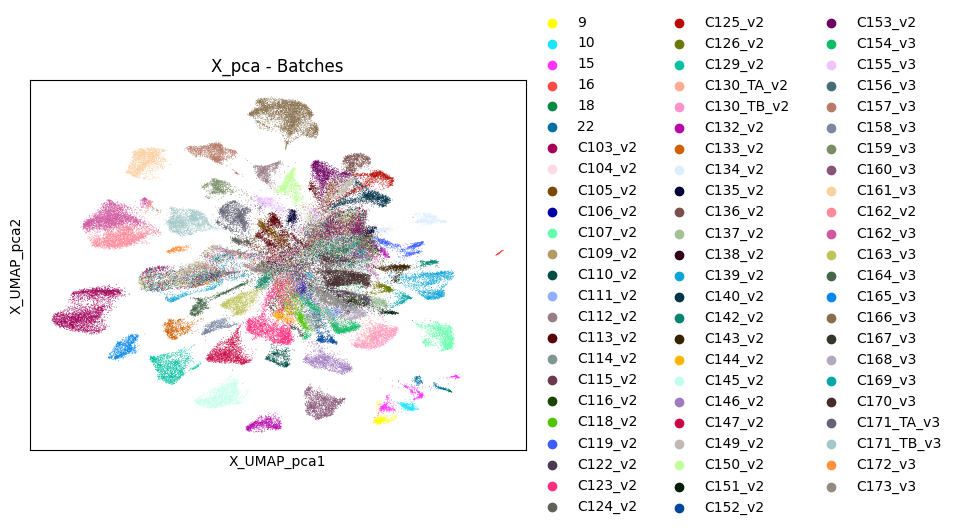

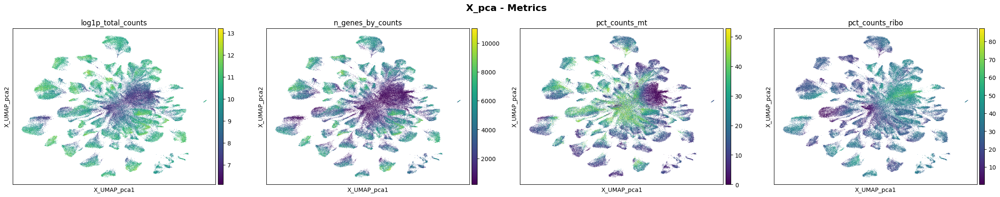

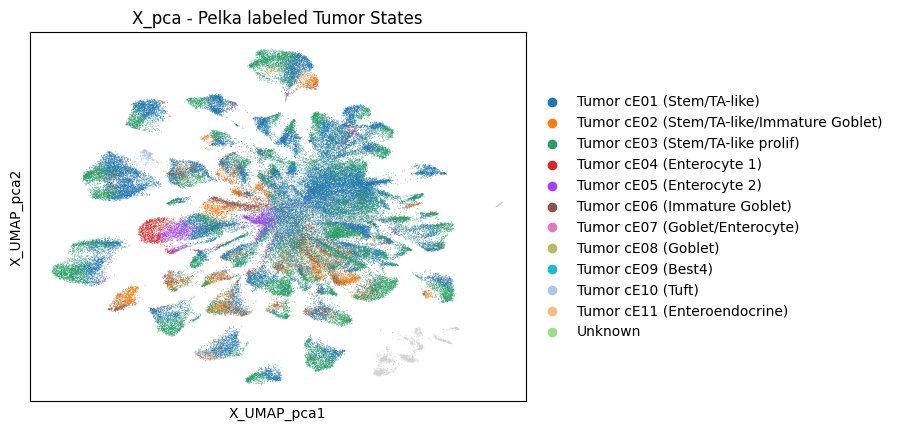

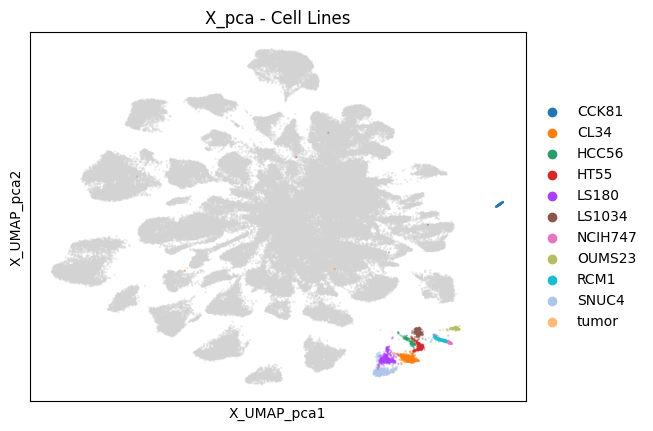

In [23]:
plot_basic_embeddings(PCA_UMAP_KEY)

## SCVI

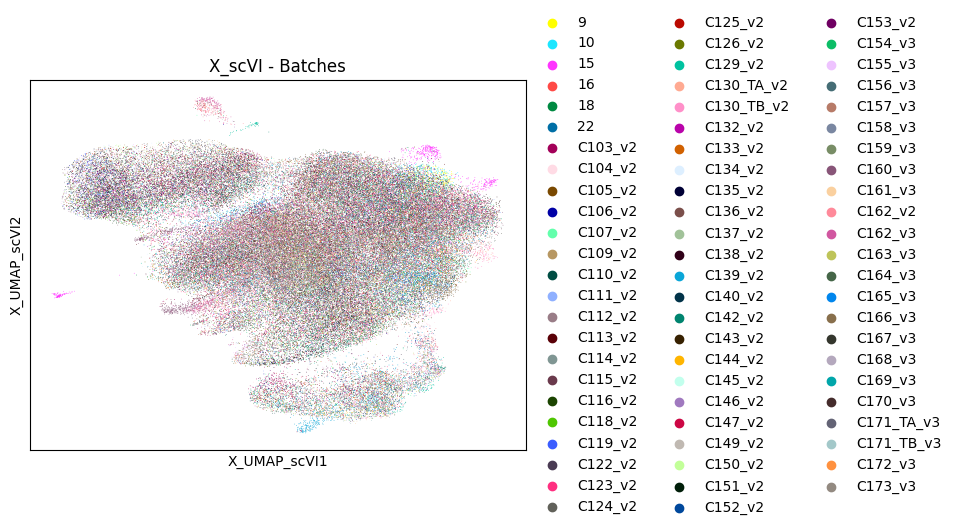

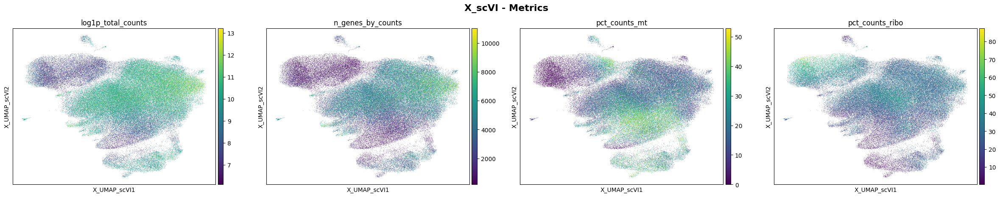

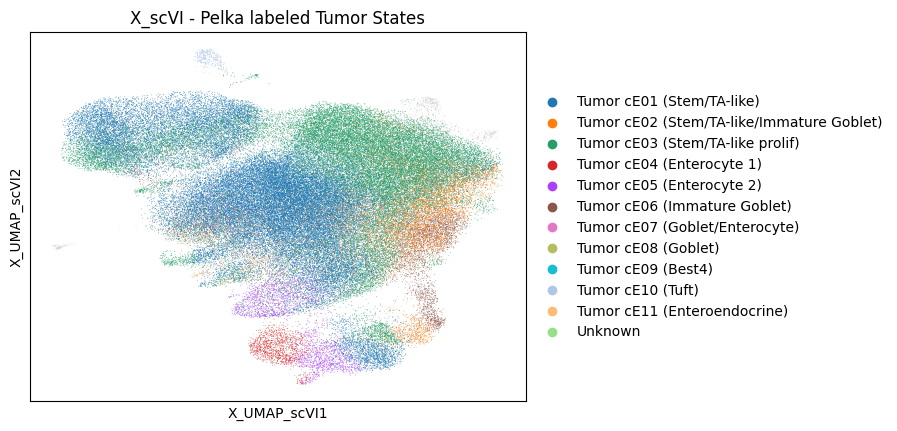

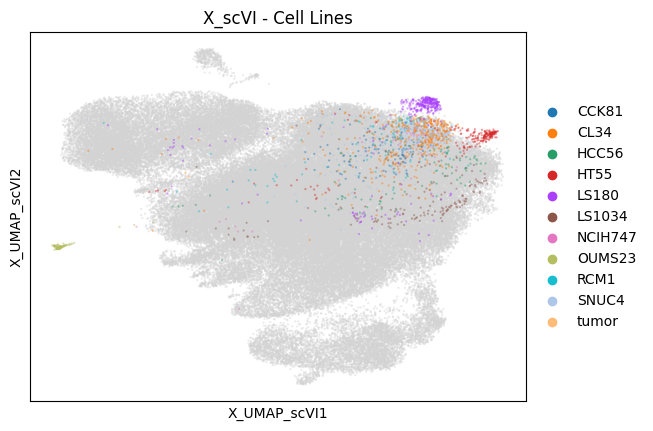

In [24]:
plot_basic_embeddings(SCVI_UMAP_KEY)

## SCANVI

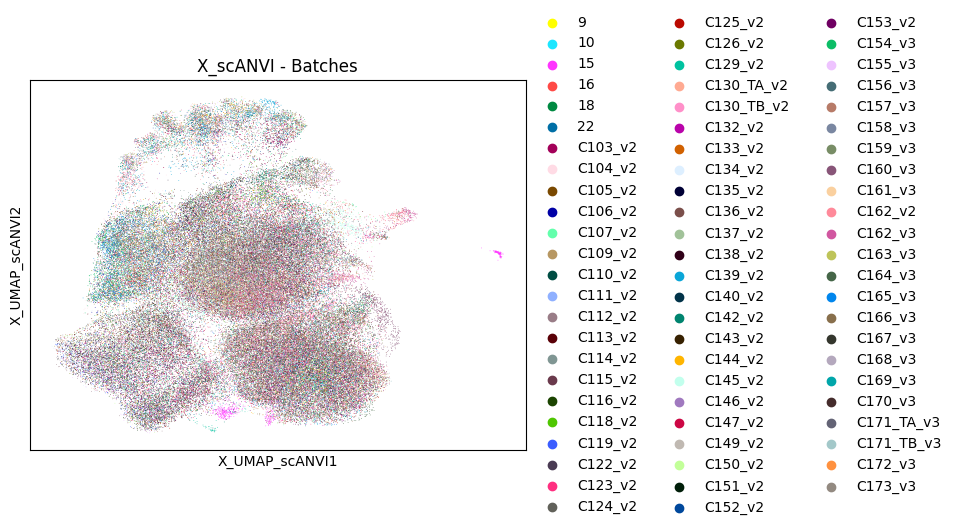

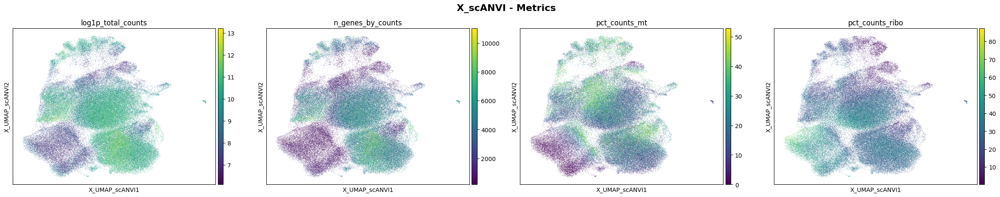

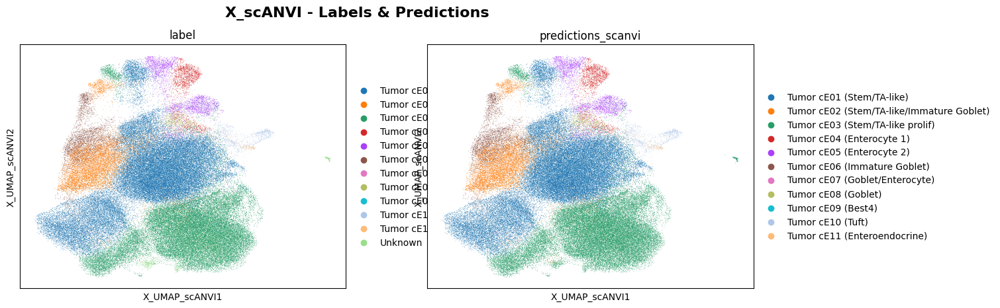

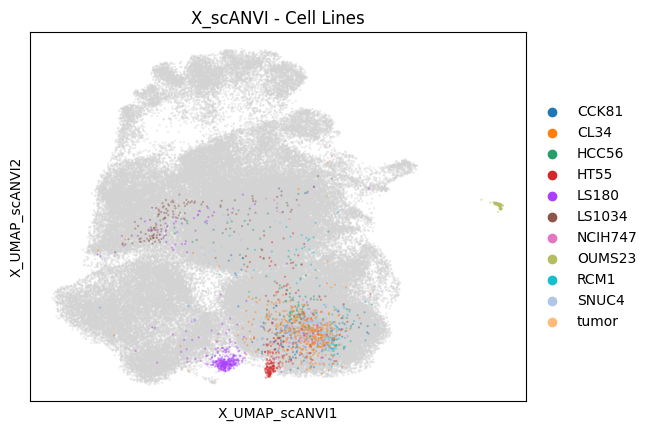

In [25]:
plot_basic_embeddings(SCANVI_UMAP_KEY, add_preds=True)

# Clustering: From single cells to clusters

In [26]:
leiden_resolutions_dict = {
    "res0_25":   0.25,
    "res0_5":    0.5,
    "res0_75":   0.75,
    "res1":      1,
    "res1_5":    1.5,
    "res2":      2,
    "res3":      3,
}

for name, v in leiden_resolutions_dict.items(): 
    sc.tl.leiden(
        combined_adata, 
        resolution=v,
        key_added=f"leiden_{name}",
        flavor="igraph", n_iterations=2, directed=False
    )

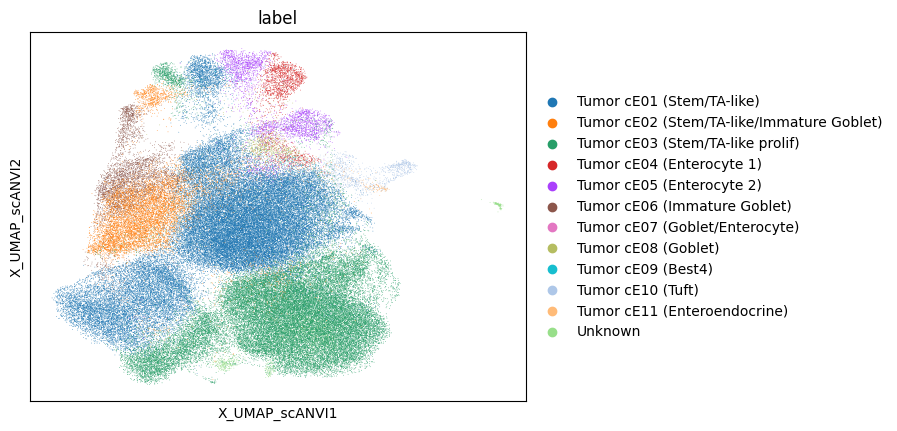

In [27]:
sc.pl.embedding(
    combined_adata,
    color=["label"],
    basis=SCANVI_UMAP_KEY,
)

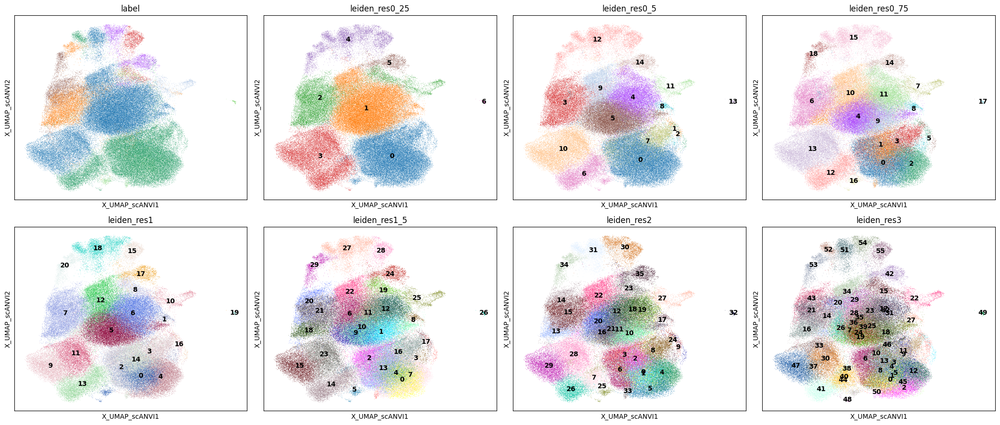

In [28]:
colors = ["label"] + ["leiden_" + el for el in list(leiden_resolutions_dict.keys())]
n = len(colors)
nrows = 2
ncols = 4

fig, axes = plt.subplots(2, 4, figsize=(5.25 * ncols, 4.5 * nrows))
axes = axes.flatten()

for ax, color in zip(axes, colors):
    legend_loc = None if color=="label" else "on data"

    sc.pl.embedding(
        combined_adata,
        basis=SCANVI_UMAP_KEY,
        color=color,
        ax=ax,
        show=False,
        legend_loc=legend_loc,
        title=color,
    )
plt.tight_layout()
plt.savefig(os.path.join("figures", "leiden_sweep.png"), dpi=150, bbox_inches="tight")
plt.show()

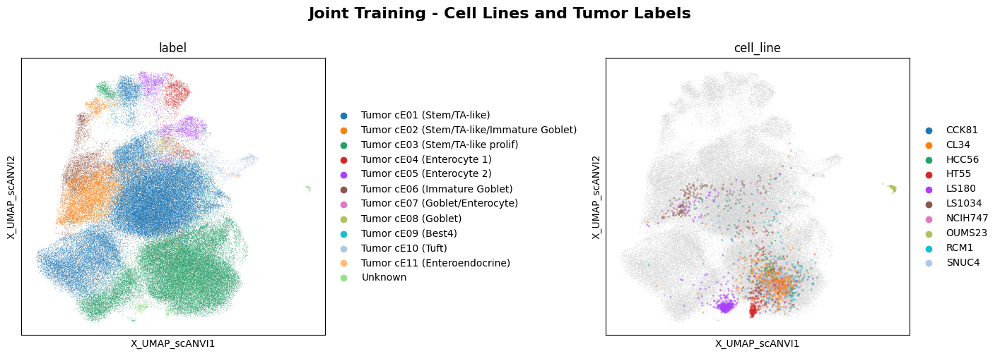

In [29]:
fig, axes= plt.subplots(1,2, figsize=(14.25,5))
axes = axes.flatten()

cell_line_mask = combined_adata.obs["dataset"] == "cell_line"
plot_view = combined_adata[cell_line_mask]

sc.pl.embedding(
    combined_adata,
    color=["label"],
    basis=SCANVI_UMAP_KEY,
    show=False,
    ax=axes[0],
)

sc.pl.embedding(
    combined_adata,
    color=None,
    basis=SCANVI_UMAP_KEY,
    show=False,
    ax=axes[1],
)
sc.pl.embedding(
    plot_view,
    color="cell_line",
    basis=SCANVI_UMAP_KEY,
    ax=axes[1],
    size=20,
    alpha=0.45,
    show=False,
)


plt.suptitle("Joint Training - Cell Lines and Tumor Labels", fontsize=16, fontweight="bold", y=1.0, x=0.5)
plt.tight_layout()
plt.savefig(os.path.join("figures", "joint_integration.png"), dpi=150, bbox_inches="tight")
plt.show()

## Tumor subpopulations guided by Pelka et al. Labels
In my opinion resolution 1 has the best clusters considering only the tumor cells. Taking the cell lines into considerations is more nuisanced as most cell line cells fall into two only leiden_res1 clusters, namely 0 and 2, though that does not change really change with an increased resolution. Most cell line cells just cluster to each other as expected.

In [30]:
selected_leiden = "leiden_res1"

combined_adata.obs["assigned_cluster"] = combined_adata.obs[selected_leiden].astype(str).where(
    combined_adata.obs["dataset"] == "tumor",
    other="not assigned"
)

combined_adata.obs["assigned_cluster"] = combined_adata.obs["assigned_cluster"].astype("category")

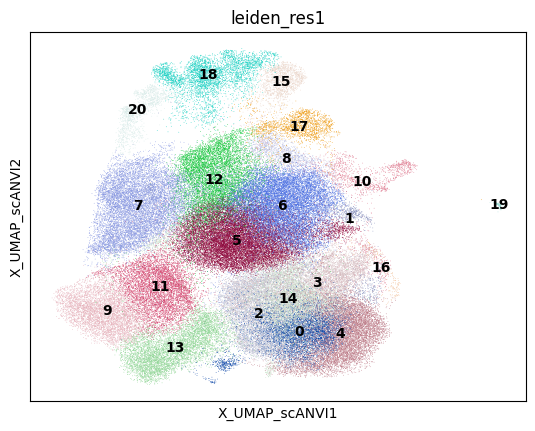

In [31]:
sc.pl.embedding(
    combined_adata,
    color=selected_leiden,
    basis=SCANVI_UMAP_KEY,
    legend_loc="on data",
)

## Cell Line Subpopulations
Here we pick for each cell line suitable subpopulations. As we only have 10 cell lines in this dataset we pick these cell groups for each cell line manually. Should we include more cell lines later a better approach would be to set a lower bound for the number of cells that must be inside a leiden cluster to be actually considered. I think a threshold in the range of ~50 cells is an appropriate choice (especially if we consider that we removed cell lines with less than 50 cells in the PP).

We go from single cells to clusters by picking the cells from a cell line that belong to the same leiden cluster. Utilizing a threshold to make sure that we ignore noise and obtain a more faithful centroid for the matching later.

In [32]:
def plot_leiden_per_cell_line(cell_line):
    plot_colors = [selected_leiden, SCANVI_PREDICTIONS_KEY]
    titles = [f"{cell_line} - Leiden Cluster", f"{cell_line} - scANVI Predictions"]
    
    cell_line_mask = combined_adata.obs["cell_line"] == cell_line
    plot_view = combined_adata[cell_line_mask]

    print(f"State Predictions for {cell_line}")
    print(plot_view.obs[SCANVI_PREDICTIONS_KEY].value_counts())
    print("\n", plot_view.obs[selected_leiden].value_counts())
    
    fig, axes= plt.subplots(1,2, figsize=(14.25,5))
    for ax, color, title in zip(axes, plot_colors, titles):
        sc.pl.embedding(
            combined_adata,
            color=None,
            basis=SCANVI_UMAP_KEY,
            show=False,
            ax=ax,
        )
    
        sc.pl.embedding(
            plot_view,
            color=color,
            basis=SCANVI_UMAP_KEY,
            ax=ax,
            title=title,
            size=20,
            alpha=0.45,
            show=False,
        )
    
    plt.tight_layout()
    plt.show()

### SNUC4

State Predictions for SNUC4
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    438
Tumor cE01 (Stem/TA-like)            33
Name: count, dtype: int64

 leiden_res1
0     397
4      33
6      15
5      11
2       8
14      3
9       1
11      1
12      1
13      1
Name: count, dtype: int64


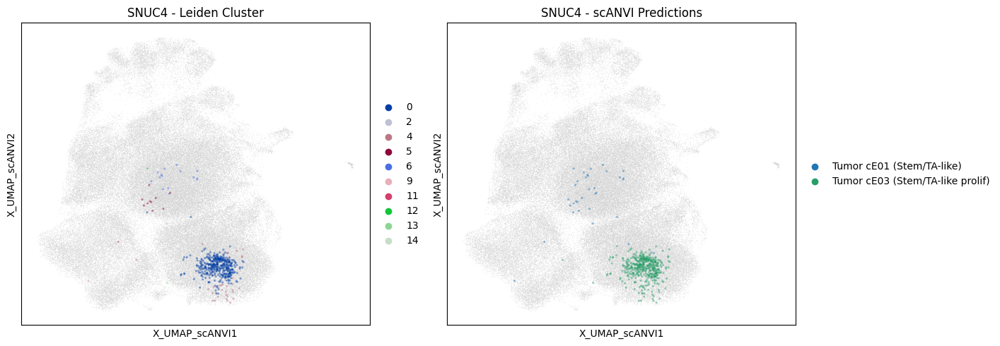

In [33]:
plot_leiden_per_cell_line("SNUC4")

### CL34

State Predictions for CL34
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)             406
Tumor cE01 (Stem/TA-like)                      9
Tumor cE02 (Stem/TA-like/Immature Goblet)      2
Tumor cE10 (Tuft)                              1
Name: count, dtype: int64

 leiden_res1
0     330
4      39
2      14
14     10
3       8
13      8
6       3
7       2
5       2
9       1
8       1
Name: count, dtype: int64


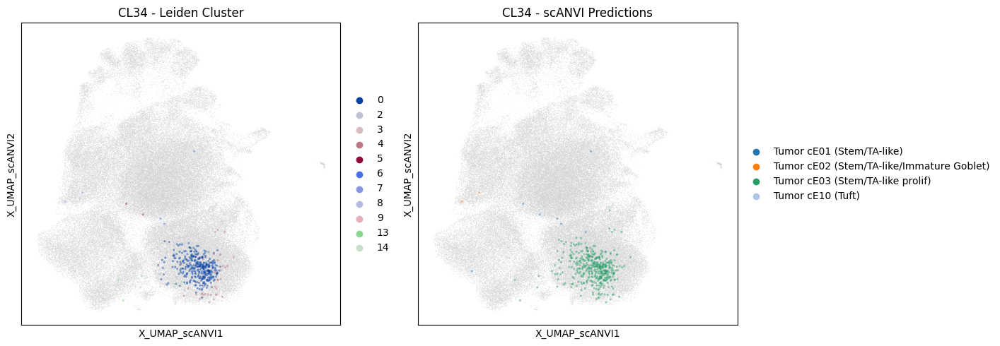

In [34]:
plot_leiden_per_cell_line("CL34")

### LS180

State Predictions for LS180
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)             276
Tumor cE02 (Stem/TA-like/Immature Goblet)     55
Tumor cE01 (Stem/TA-like)                     28
Tumor cE11 (Enteroendocrine)                   2
Tumor cE06 (Immature Goblet)                   1
Name: count, dtype: int64

 leiden_res1
0     282
13     26
6      21
7      17
5       6
2       3
4       3
10      2
3       1
14      1
Name: count, dtype: int64


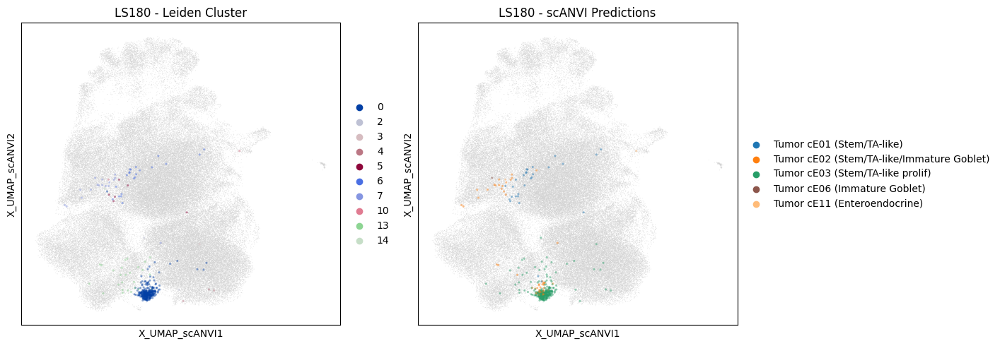

In [35]:
plot_leiden_per_cell_line("LS180")

### HT55

State Predictions for HT55
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    185
Tumor cE01 (Stem/TA-like)            26
Name: count, dtype: int64

 leiden_res1
14    172
2      13
5      12
4      10
6       3
0       1
Name: count, dtype: int64


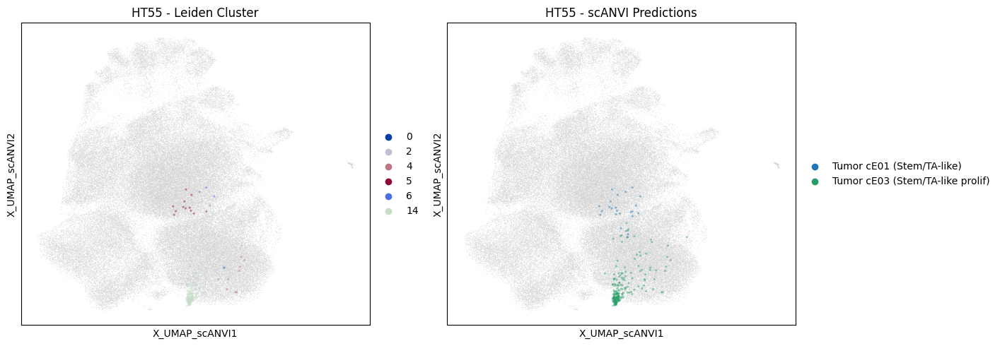

In [36]:
plot_leiden_per_cell_line("HT55")

### LS1034

State Predictions for LS1034
predictions_scanvi
Tumor cE02 (Stem/TA-like/Immature Goblet)    90
Tumor cE01 (Stem/TA-like)                    41
Tumor cE03 (Stem/TA-like prolif)             16
Tumor cE06 (Immature Goblet)                  3
Tumor cE11 (Enteroendocrine)                  2
Tumor cE10 (Tuft)                             1
Name: count, dtype: int64

 leiden_res1
7     77
6     34
14    26
5      6
4      4
0      2
10     2
12     2
Name: count, dtype: int64


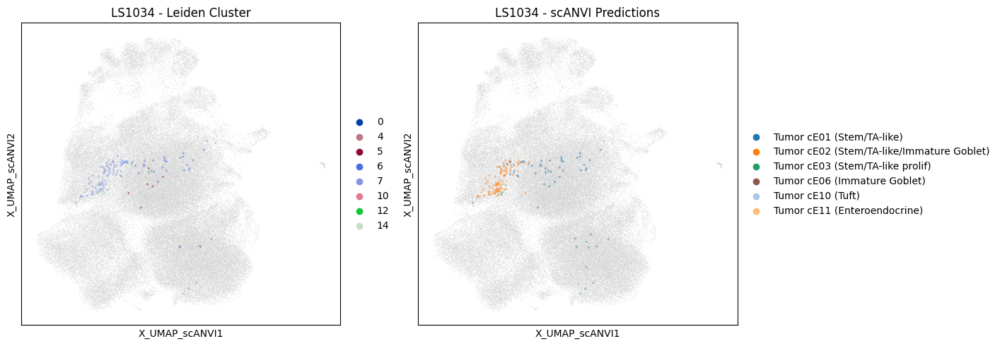

In [37]:
plot_leiden_per_cell_line("LS1034")

### RCM1

State Predictions for RCM1
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    107
Tumor cE01 (Stem/TA-like)            24
Name: count, dtype: int64

 leiden_res1
0     69
4     23
6     13
2     10
5      7
14     6
9      1
11     1
13     1
Name: count, dtype: int64


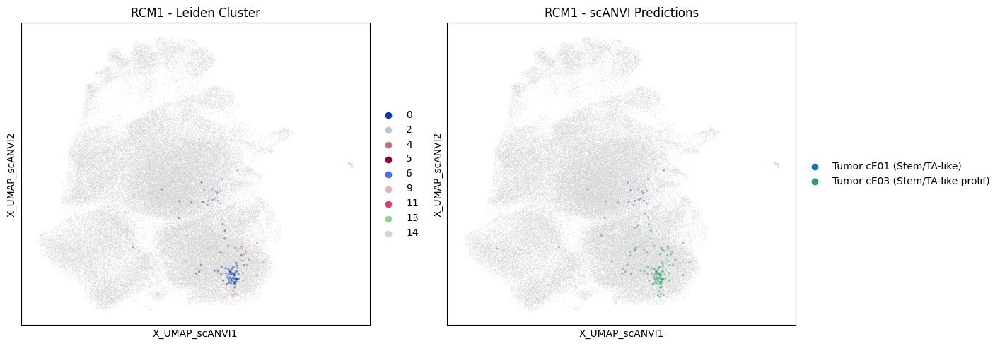

In [38]:
plot_leiden_per_cell_line("RCM1")

### CCK81

State Predictions for CCK81
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    119
Tumor cE01 (Stem/TA-like)             8
Name: count, dtype: int64

 leiden_res1
0    82
4    30
2     7
5     7
6     1
Name: count, dtype: int64


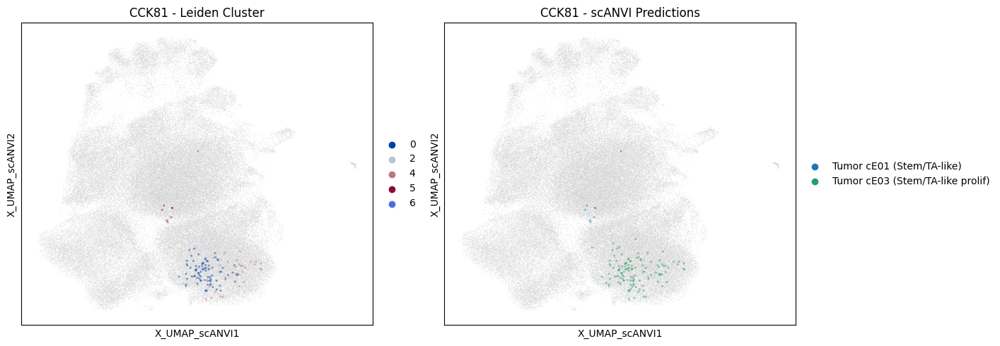

In [39]:
plot_leiden_per_cell_line("CCK81")

### OUMS23

State Predictions for OUMS23
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    87
Tumor cE01 (Stem/TA-like)           15
Tumor cE10 (Tuft)                    5
Name: count, dtype: int64

 leiden_res1
19    105
6       1
17      1
Name: count, dtype: int64


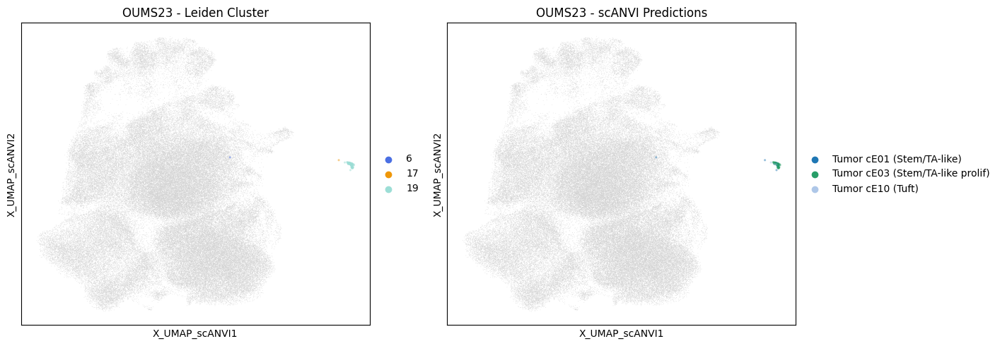

In [40]:
plot_leiden_per_cell_line("OUMS23")

### HCC56

State Predictions for HCC56
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)             65
Tumor cE01 (Stem/TA-like)                    30
Tumor cE02 (Stem/TA-like/Immature Goblet)     7
Name: count, dtype: int64

 leiden_res1
14    56
6     13
4     13
5      9
7      8
2      2
0      1
Name: count, dtype: int64


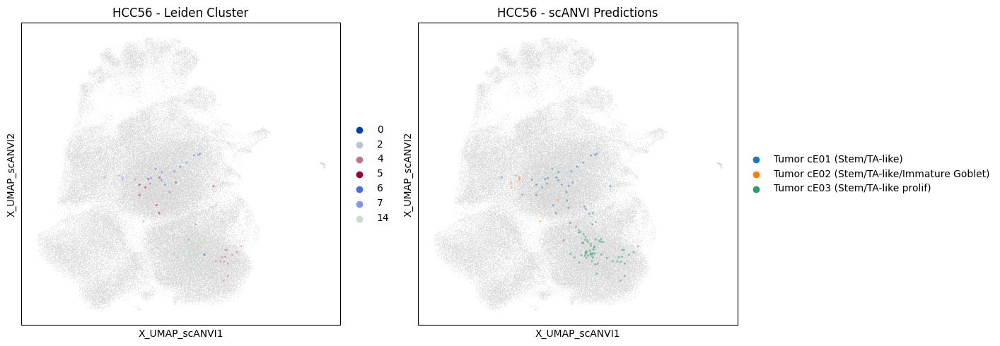

In [41]:
plot_leiden_per_cell_line("HCC56")

### NCIH747

State Predictions for NCIH747
predictions_scanvi
Tumor cE03 (Stem/TA-like prolif)    72
Tumor cE01 (Stem/TA-like)            8
Name: count, dtype: int64

 leiden_res1
0     60
6      7
14     5
4      5
17     2
2      1
Name: count, dtype: int64


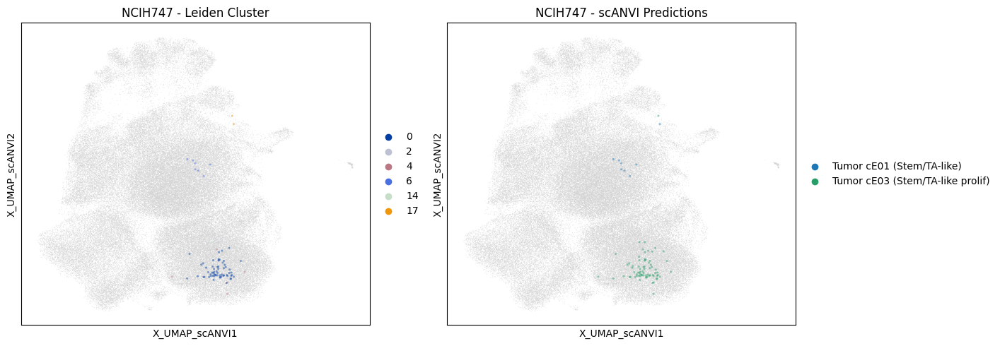

In [42]:
plot_leiden_per_cell_line("NCIH747")

## Cells to Clusters

In [43]:
cl_threshold = 50

cell_lines_mask = combined_adata.obs["dataset"] == "cell_line"
cell_obs = combined_adata.obs.loc[cell_lines_mask].copy()

cell_obs["group_size"] = cell_obs.groupby(
    ["cell_line", selected_leiden],
    observed=False
)[selected_leiden].transform("count")

# need to convert to string or new categories alignment
combined_adata.obs["assigned_cluster"] = combined_adata.obs["assigned_cluster"].astype(str)

valid = cell_obs["group_size"] > cl_threshold
combined_adata.obs.loc[cell_obs.index[valid], "assigned_cluster"] = (
    cell_obs.loc[valid, "cell_line"].astype(str) + "_" + 
    cell_obs.loc[valid, selected_leiden].astype(str)
)

combined_adata.obs["assigned_cluster"] = combined_adata.obs["assigned_cluster"].astype("category")

### Better tumor cluster names

In [44]:
composition = pd.crosstab(
    combined_adata.obs["assigned_cluster"],
    combined_adata.obs["label"]
)

composition = composition.drop(columns=["Unknown"])
composition = composition.loc[(composition!=0).any(axis=1)]

In [45]:
composition

label,Tumor cE01 (Stem/TA-like),Tumor cE02 (Stem/TA-like/Immature Goblet),Tumor cE03 (Stem/TA-like prolif),Tumor cE04 (Enterocyte 1),Tumor cE05 (Enterocyte 2),Tumor cE06 (Immature Goblet),Tumor cE07 (Goblet/Enterocyte),Tumor cE08 (Goblet),Tumor cE09 (Best4),Tumor cE10 (Tuft),Tumor cE11 (Enteroendocrine)
assigned_cluster,,,,,,,,,,,
0,26,17,4617,0,0,0,0,0,0,0,0
1,533,107,369,0,0,14,0,0,0,2,2
10,46,12,453,0,3,16,0,1,0,1025,184
11,5901,4,108,6,0,20,0,3,26,76,3
12,7490,164,66,2,36,17,0,1,3,5,15
13,451,95,5615,0,1,44,0,0,2,93,4
14,613,747,4947,0,0,0,0,0,1,0,1
15,4,1,1,1284,39,0,31,57,14,0,1
16,49,0,170,0,0,0,0,0,0,0,0


In [46]:
composition = composition.div(composition.sum(axis=1), axis=0)
composition

label,Tumor cE01 (Stem/TA-like),Tumor cE02 (Stem/TA-like/Immature Goblet),Tumor cE03 (Stem/TA-like prolif),Tumor cE04 (Enterocyte 1),Tumor cE05 (Enterocyte 2),Tumor cE06 (Immature Goblet),Tumor cE07 (Goblet/Enterocyte),Tumor cE08 (Goblet),Tumor cE09 (Best4),Tumor cE10 (Tuft),Tumor cE11 (Enteroendocrine)
assigned_cluster,,,,,,,,,,,
0,0.005579,0.003648,0.990773,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.518987,0.104187,0.359299,0.000000,0.000000,0.013632,0.000000,0.000000,0.000000,0.001947,0.001947
10,0.026437,0.006897,0.260345,0.000000,0.001724,0.009195,0.000000,0.000575,0.000000,0.589080,0.105747
11,0.959980,0.000651,0.017570,0.000976,0.000000,0.003254,0.000000,0.000488,0.004230,0.012364,0.000488
12,0.960380,0.021028,0.008463,0.000256,0.004616,0.002180,0.000000,0.000128,0.000385,0.000641,0.001923
13,0.071531,0.015067,0.890563,0.000000,0.000159,0.006979,0.000000,0.000000,0.000317,0.014750,0.000634
14,0.097163,0.118402,0.784118,0.000000,0.000000,0.000000,0.000000,0.000000,0.000159,0.000000,0.000159
15,0.002793,0.000698,0.000698,0.896648,0.027235,0.000000,0.021648,0.039804,0.009777,0.000000,0.000698
16,0.223744,0.000000,0.776256,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [47]:
cluster_to_mainlabel = (
    composition
    .idxmax(axis=1)
    .to_dict()
)

tumor_cluster_name_dict = {
    cluster: f"{cluster}_{label}"
    for cluster, label in cluster_to_mainlabel.items()
}

for cluster, name in tumor_cluster_name_dict.items():
    match = re.search(r"\((.*?)\)", name)
    
    if match:
        cell_type = match.group(1)
        tumor_cluster_name_dict[cluster] = f"{cluster}_{cell_type}"
    else:
        tumor_cluster_name_dict[cluster] = str(cluster)


tumor_cluster_name_dict


{
    '0': '0_Stem/TA-like prolif',
    '1': '1_Stem/TA-like',
    '10': '10_Tuft',
    '11': '11_Stem/TA-like',
    '12': '12_Stem/TA-like',
    '13': '13_Stem/TA-like prolif',
    '14': '14_Stem/TA-like prolif',
    '15': '15_Enterocyte 1',
    '16': '16_Stem/TA-like prolif',
    '17': '17_Enterocyte 2',
    '18': '18_Stem/TA-like',
    '2': '2_Stem/TA-like prolif',
    '20': '20_Immature Goblet',
    '3': '3_Stem/TA-like prolif',
    '4': '4_Stem/TA-like prolif',
    '5': '5_Stem/TA-like',
    '6': '6_Stem/TA-like',
    '7': '7_Stem/TA-like/Immature Goblet',
    '8': '8_Goblet',
    '9': '9_Stem/TA-like'
}

### Cluster Centroids

In [48]:
def compute_cluster_centroid(adata):
    X_latent = combined_adata.obsm[SCANVI_LATENT_KEY]

    clusters = combined_adata.obs["assigned_cluster"].values
    unique_clusters = np.unique(clusters)
    centroids_dict = {}
    
    for cluster in unique_clusters:
        idx = np.where(clusters == cluster)[0]
        X_subset = X_latent[idx, :]
    
        centroid = X_subset.mean(axis=0)
        centroids_dict[cluster] = centroid
    return centroids_dict

centroids_dict = compute_cluster_centroid(combined_adata)

In [49]:
def is_tumor_cluster(cluster_id):
    return cluster_id.isdigit()

# rename for prettier plots
cluster_ids = list(centroids_dict.keys())
tumor_clusters = [c for c in cluster_ids if is_tumor_cluster(c)]
cl_clusters = [c for c in cluster_ids if not is_tumor_cluster(c)]

tumor_sorted = sorted(tumor_clusters, key=lambda x: int(x))
cl_sorted = sorted(cl_clusters)
ordered_clusters = tumor_sorted + cl_sorted

centroid_list = [centroids_dict[c] for c in ordered_clusters]

In [50]:
# maybe no major cell type label is better for tumor, just set to ordered_clusters then
ordered_clusters_name = [
    tumor_cluster_name_dict.get(x,x) for x in ordered_clusters
]

# ordered_clusters_name = ordered_clusters

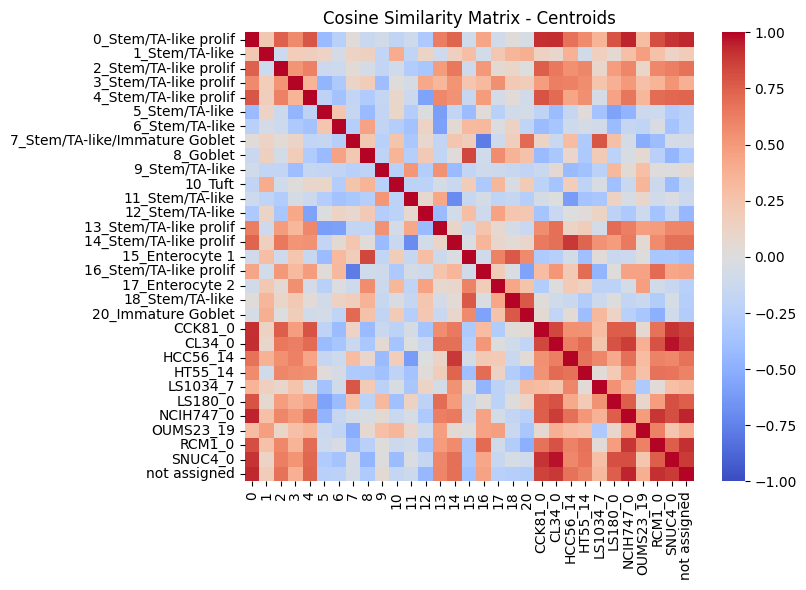

In [51]:
centroid_sim = cosine_similarity(centroid_list, centroid_list)
sim_df = pd.DataFrame(
    centroid_sim,
    index=ordered_clusters_name,
    columns=ordered_clusters
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_df,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=False,          # set to True if you want numbers in each cell
    square=True,          # makes cells square
    cbar=True,
    xticklabels=True,
    yticklabels=True
)
plt.title('Cosine Similarity Matrix - Centroids')
plt.tight_layout()
plt.show()

### Cluster Medoid

In [52]:
def compute_cluster_medoid(adata):
    X_latent = adata.obsm[SCANVI_LATENT_KEY]

    clusters = adata.obs["assigned_cluster"].values
    unique_clusters = np.unique(clusters)
    medoids_dict = {}
    
    for cluster in unique_clusters:     
        idx = np.where(clusters == cluster)[0]
        X_subset = X_latent[idx, :]
    
        dist_matrix = pairwise_distances(X_subset, metric="euclidean")
        total_dists = dist_matrix.sum(axis=1)
    
        medoid_idx_local = np.argmin(total_dists)
        medoid_idx_global = idx[medoid_idx_local] # map back to combined_adata idx
        medoids_dict[cluster] = medoid_idx_global
    return medoids_dict

medoids_idx_dict = compute_cluster_medoid(combined_adata)
medoids_dict = {}
for k,v in medoids_idx_dict.items():
    medoids_dict[k] = combined_adata.obsm[SCANVI_LATENT_KEY][v]

combined_adata.obs["is_medoid"] = False
medoid_indices = list(medoids_idx_dict.values())
combined_adata.obs.iloc[medoid_indices, combined_adata.obs.columns.get_loc("is_medoid")] = True

In [53]:
# rename for prettier plots
medoid_list = [medoids_dict[c] for c in ordered_clusters]

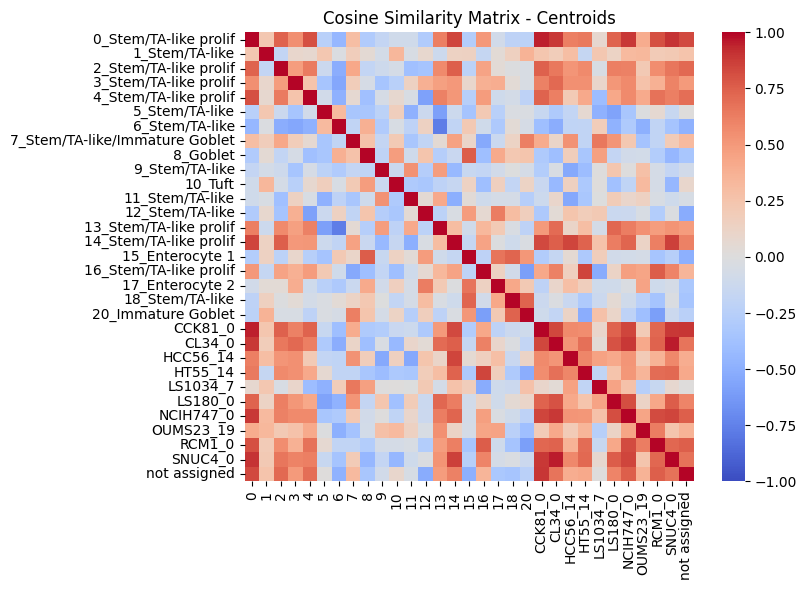

In [54]:
medoid_sim = cosine_similarity(medoid_list, medoid_list)

sim_df = pd.DataFrame(
    medoid_sim,
    index=ordered_clusters_name,
    columns=ordered_clusters
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_df,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    annot=False,
    square=True,
    cbar=True,
    xticklabels=True,
    yticklabels=True
)
plt.title('Cosine Similarity Matrix - Centroids')
plt.tight_layout()
plt.show()

# Matching: Cell Line Cluster to Tumor Cluster

## Euclidean 

In [55]:
tumor_sorted_name = [
    tumor_cluster_name_dict.get(x,x) for x in tumor_sorted
]

In [56]:
tumor_centroids = [centroids_dict[c] for c in tumor_sorted]
cl_centroids = [centroids_dict[c] for c in cl_sorted]
centroid_euclidean = cdist(tumor_centroids, cl_centroids, metric="euclidean")

tumor_medoids = [medoids_dict[c] for c in tumor_sorted]
cl_medoids = [medoids_dict[c] for c in cl_sorted]
medoid_euclidean = cdist(tumor_medoids, cl_medoids, metric="euclidean")

centroid_euclidean_df = pd.DataFrame(
    centroid_euclidean,
    index=tumor_sorted_name,
    columns=cl_sorted
)
centroid_euclidean_df.drop(columns=["not assigned"], inplace=True)

medoid_euclidean_df = pd.DataFrame(
    medoid_euclidean,
    index=tumor_sorted_name,
    columns=cl_sorted
)
medoid_euclidean_df.drop(columns=["not assigned"], inplace=True)

best_euclidean_centroid = centroid_euclidean_df.idxmin(axis=0)
best_euclidean_medoid = medoid_euclidean_df.idxmin(axis=0)

### Centroid

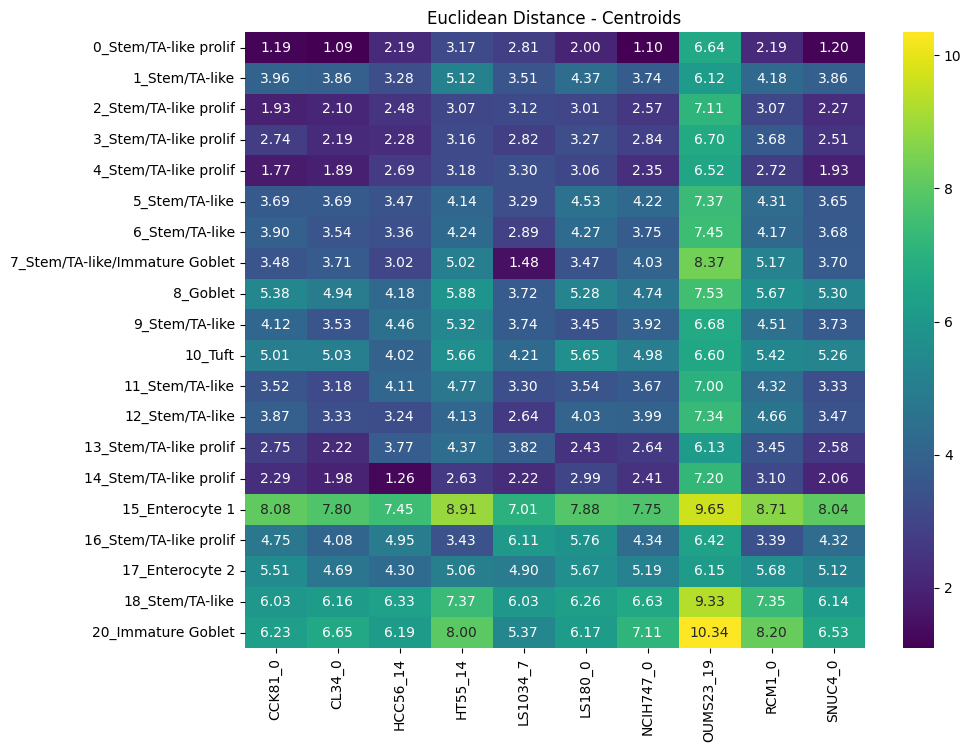

In [57]:
plt.figure(figsize=(10, 8))
sns.heatmap(centroid_euclidean_df, annot=True, cmap='viridis', fmt='.2f')
plt.title("Euclidean Distance - Centroids")
plt.show()

In [58]:
best_euclidean_centroid


CCK81_0               0_Stem/TA-like prolif
CL34_0                0_Stem/TA-like prolif
HCC56_14             14_Stem/TA-like prolif
HT55_14              14_Stem/TA-like prolif
LS1034_7     7_Stem/TA-like/Immature Goblet
LS180_0               0_Stem/TA-like prolif
NCIH747_0             0_Stem/TA-like prolif
OUMS23_19                    1_Stem/TA-like
RCM1_0                0_Stem/TA-like prolif
SNUC4_0               0_Stem/TA-like prolif
dtype: object

### Medoid

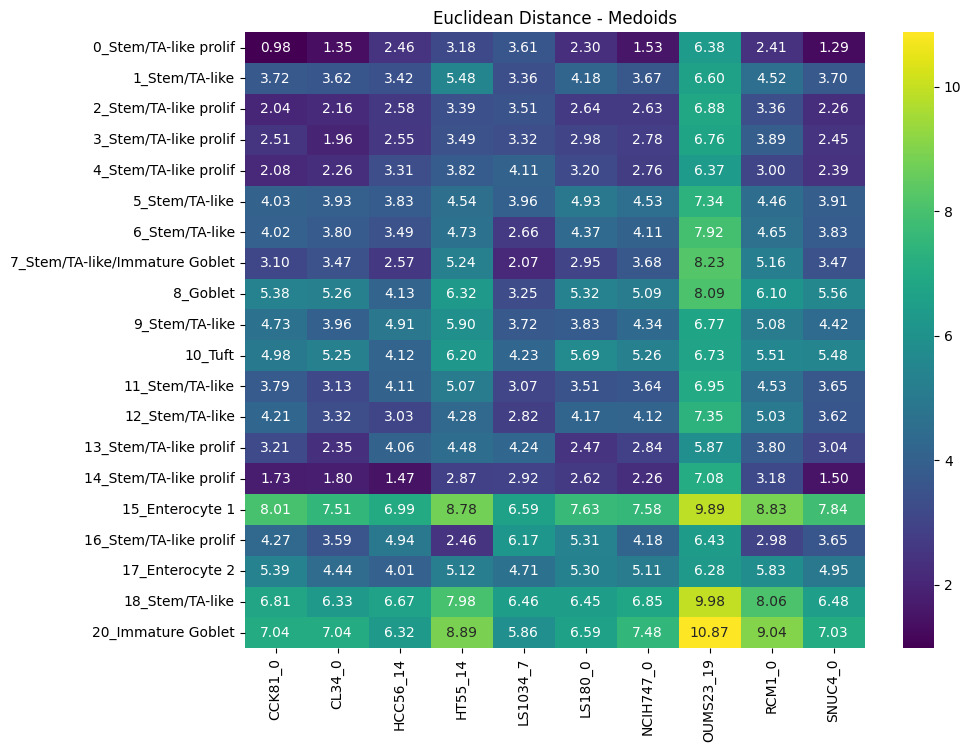

In [59]:
plt.figure(figsize=(10, 8))
sns.heatmap(medoid_euclidean_df, annot=True, cmap='viridis', fmt='.2f')
plt.title("Euclidean Distance - Medoids")
plt.show()

In [60]:
best_euclidean_medoid


CCK81_0               0_Stem/TA-like prolif
CL34_0                0_Stem/TA-like prolif
HCC56_14             14_Stem/TA-like prolif
HT55_14              16_Stem/TA-like prolif
LS1034_7     7_Stem/TA-like/Immature Goblet
LS180_0               0_Stem/TA-like prolif
NCIH747_0             0_Stem/TA-like prolif
OUMS23_19            13_Stem/TA-like prolif
RCM1_0                0_Stem/TA-like prolif
SNUC4_0               0_Stem/TA-like prolif
dtype: object

## Wasserstein
Earth Movers distance. Some nice blog posts by great researchers: 
- [Vincent Herrmann - Wasserstein](https://vincentherrmann.github.io/blog/wasserstein/)
- [Lilian Weng - Why Wasserstein is better than JS or KLD](https://lilianweng.github.io/posts/2017-08-20-gan/#what-is-wasserstein-distance)

In [61]:
# maybe look more into pot: python optimal transport library
import ot

In [62]:
cluster_cells = {}

for cluster in ordered_clusters:
    idx = combined_adata.obs["assigned_cluster"] == cluster
    cluster_cells[cluster] = combined_adata.obsm[SCANVI_LATENT_KEY][idx, :]

# for each cl compute wasserstein to tumor
wasserstein_2d = np.zeros((len(tumor_sorted), len(cl_sorted)))
for i, t_clust in enumerate(tumor_sorted):
    A = cluster_cells[t_clust]
    a = np.ones(A.shape[0]) / A.shape[0]
    for j, cl_clust in enumerate(cl_sorted):
        B = cluster_cells[cl_clust]
        b = np.ones(B.shape[0]) / B.shape[0]
        # Compute cost matrix (squared Euclidean)
        M = ot.dist(A, B, metric='euclidean')**2
        # Earth mover’s distance (2‑Wasserstein = sqrt(transport cost))
        cost = ot.emd2(a, b, M)
        wasserstein_2d[i, j] = np.sqrt(cost)

dist_df_w2 = pd.DataFrame(wasserstein_2d, index=tumor_sorted_name, columns=cl_sorted)

/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/ot/lp/_network_simplex.py:574: UserWarning: numItermax reached before optimality. Try to increase numItermax.
  check_result(result_code)


In [63]:
dist_df_w2.drop(columns=["not assigned"], inplace=True)
best_match_w2 = dist_df_w2.idxmin(axis=0)

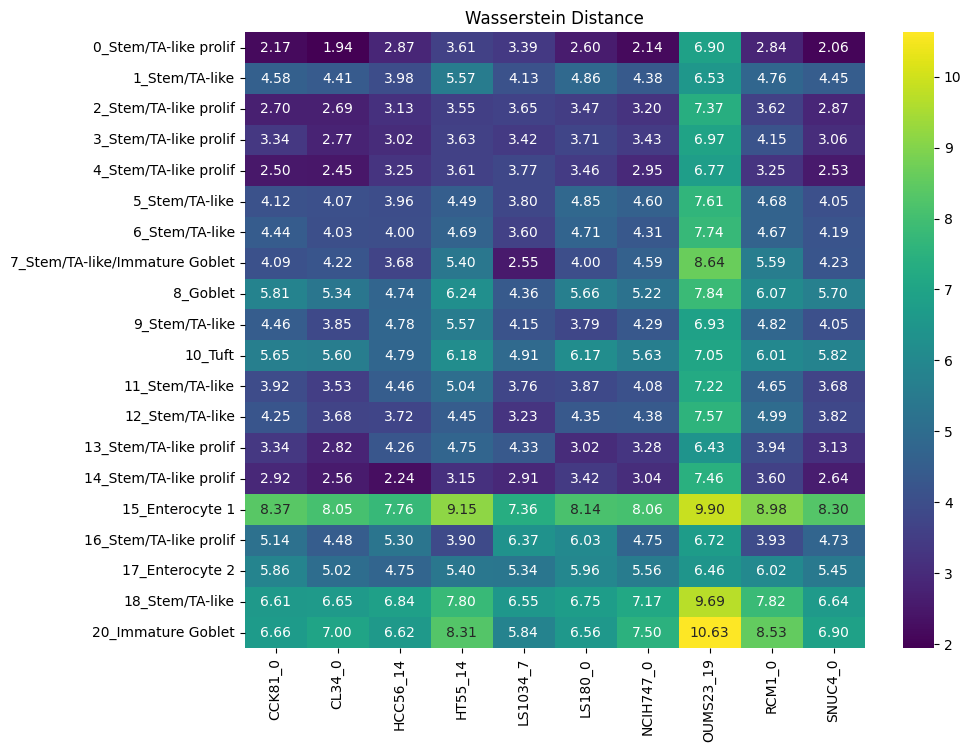

In [64]:
plt.figure(figsize=(10, 8))
sns.heatmap(dist_df_w2, annot=True, cmap='viridis', fmt='.2f')
plt.title("Wasserstein Distance")
plt.show()

In [65]:
best_match_w2


CCK81_0               0_Stem/TA-like prolif
CL34_0                0_Stem/TA-like prolif
HCC56_14             14_Stem/TA-like prolif
HT55_14              14_Stem/TA-like prolif
LS1034_7     7_Stem/TA-like/Immature Goblet
LS180_0               0_Stem/TA-like prolif
NCIH747_0             0_Stem/TA-like prolif
OUMS23_19            13_Stem/TA-like prolif
RCM1_0                0_Stem/TA-like prolif
SNUC4_0               0_Stem/TA-like prolif
dtype: object

# Summary

In [66]:
comparison = pd.DataFrame({
    "Euclidean_medoid": best_euclidean_medoid,
    "Euclidean_centroid": best_euclidean_centroid,
    "Wasserstein_2D": best_match_w2
})
comparison

,Euclidean_medoid,Euclidean_centroid,Wasserstein_2D
CCK81_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif
CL34_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif
HCC56_14,14_Stem/TA-like prolif,14_Stem/TA-like prolif,14_Stem/TA-like prolif
HT55_14,16_Stem/TA-like prolif,14_Stem/TA-like prolif,14_Stem/TA-like prolif
LS1034_7,7_Stem/TA-like/Immature Goblet,7_Stem/TA-like/Immature Goblet,7_Stem/TA-like/Immature Goblet
LS180_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif
NCIH747_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif
OUMS23_19,13_Stem/TA-like prolif,1_Stem/TA-like,13_Stem/TA-like prolif
RCM1_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif
SNUC4_0,0_Stem/TA-like prolif,0_Stem/TA-like prolif,0_Stem/TA-like prolif


# Normalized Gene Expressions
Normalized, decoded expressions. conditions on batch. Library size=1.

In [67]:
normal_expr = scanvi_joint.get_normalized_expression(library_size=1e4)

In [68]:
cluster_means = {}
for cluster in ordered_clusters:
    if cluster == "not assigned":
        continue

    idx = combined_adata.obs["assigned_cluster"] == cluster
    cluster_means[cluster] = normal_expr.loc[idx].mean(axis=0)

cluster_means = pd.DataFrame(cluster_means).T

In [69]:
cos_sim = cosine_similarity(cluster_means)

cos_sim = pd.DataFrame(
    cos_sim,
    index = cluster_means.index,
    columns=cluster_means.index,
)

In [70]:
cos_sim.index = [
    tumor_cluster_name_dict.get(x,x) for x in cos_sim.index
]

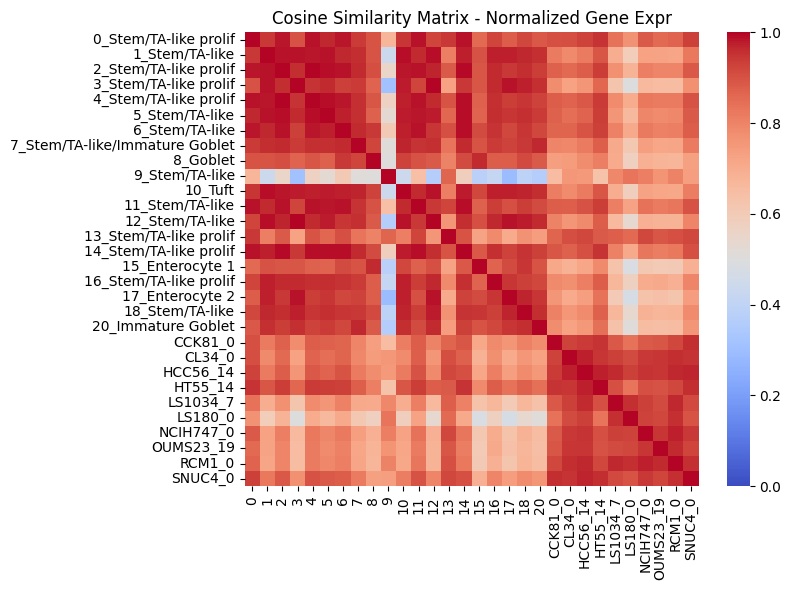

In [71]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    cos_sim,
    cmap='coolwarm',
    vmin=0, vmax=1,
    annot=False,
    square=True,
    cbar=True,
    xticklabels=True,
    yticklabels=True
)
plt.title('Cosine Similarity Matrix - Normalized Gene Expr')
plt.tight_layout()
plt.show()

# scIB

In [62]:
keep_obs = ["dataset", "batch", "label"]
for col in list(combined_adata.obs.columns):
    if col not in keep_obs:
        del combined_adata.obs[col]

keep_obsm = ["X_pca", SCVI_LATENT_KEY, SCANVI_LATENT_KEY]
for key in list(combined_adata.obsm.keys()):
    if key not in keep_obsm:
        del combined_adata.obsm[key]

combined_adata.varm = {}
combined_adata.uns = {}
combined_adata.uns = {}
combined_adata.layers = {}

In [67]:
import time

labeled_cells = combined_adata.obs["dataset"] == "tumor"
adata_labeled = combined_adata[labeled_cells].copy()

bio_metrics = BioConservation(
    isolated_labels=True,
    nmi_ari_cluster_labels_leiden=False,
    nmi_ari_cluster_labels_kmeans=True,
    silhouette_label=True,
    clisi_knn=True,
)

batch_metrics = BatchCorrection(
    bras=True,
    ilisi_knn=True,
    kbet_per_label=True,
    graph_connectivity=True,
    pcr_comparison=True,
)

bm_labeled = Benchmarker(
    adata=adata_labeled,
    batch_key="batch",
    label_key="label",
    bio_conservation_metrics=bio_metrics,
    batch_correction_metrics=batch_metrics,
    embedding_obsm_keys=["X_pca", SCVI_LATENT_KEY, SCANVI_LATENT_KEY],
    pre_integrated_embedding_obsm_key="X_pca",
    n_jobs=-1,
)

bm_full = Benchmarker(
    adata=combined_adata,
    batch_key="batch",
    label_key="label",
    bio_conservation_metrics=None,
    batch_correction_metrics=BatchCorrection(
        ilisi_knn=True, pcr_comparison=True,
    ),
    embedding_obsm_keys=["X_pca", SCVI_LATENT_KEY, SCANVI_LATENT_KEY],
    pre_integrated_embedding_obsm_key="X_pca",
    n_jobs=-1,
)


start = time.time()
bm_labeled.benchmark()
bm_full.benchmark()
end = time.time()
print(f"Time: {int((end - start) / 60)} min {int((end - start) % 60)} sec")

Metrics:   0%|                                                | 0/10 [00:00<?, ?it/s, Bio conservation: isolated_labels]WARNING:jax._src.xla_bridge:An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:  70%|█████████████████████████▏          | 7/10 [29:47<05:58, 119.38s/it, Batch correction: graph_connectivity]/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/scib_metrics/metrics/_graph_connectivity.py:32: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(comps)

Embeddings:  33%|███████████████████████▋                                               | 1/3 [29:49<59:39, 1789.77s/it]
                                                                                                                        
Metrics:  70%|█████████████████████████▉           | 7/10 [02:51<01:14, 24.99s/it, Batch correc

Time: 40 min 47 sec


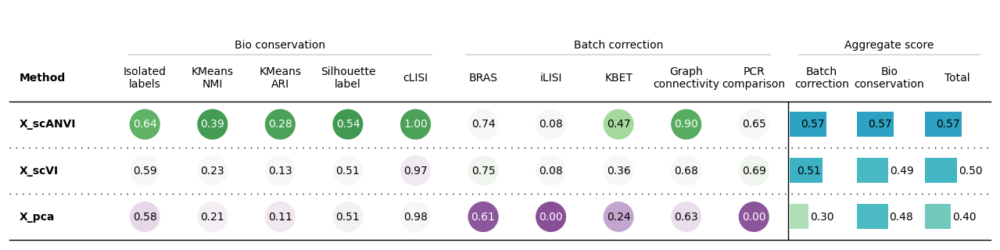

In [68]:
bm_labeled.plot_results_table(min_max_scale=False)

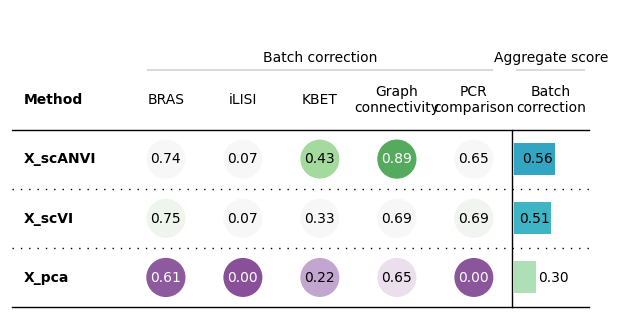

In [69]:
bm_full.plot_results_table(min_max_scale=False)

In [41]:
import time

combined_adata.obsm["Unintegrated"] = combined_adata.obsm["X_pca"]

biocons = BioConservation()

batchcons = BatchCorrection()

start = time.time()
bm = Benchmarker(
    combined_adata,
    batch_key="batch",
    label_key="label",
    bio_conservation_metrics=biocons,
    batch_correction_metrics=batchcons,
    embedding_obsm_keys=["Unintegrated", SCVI_LATENT_KEY, SCANVI_LATENT_KEY],
    pre_integrated_embedding_obsm_key="X_pca",
    n_jobs=-1,
)

bm.benchmark()
end = time.time()
print(f"Time: {int((end - start) / 60)} min {int((end - start) % 60)} sec")

Metrics:   0%|                                                | 0/10 [00:00<?, ?it/s, Bio conservation: isolated_labels]WARNING:jax._src.xla_bridge:An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.

Metrics:  70%|█████████████████████████▏          | 7/10 [30:34<06:13, 124.43s/it, Batch correction: graph_connectivity]/mnt/bigdisk/markus/miniconda3/envs/scvi/lib/python3.11/site-packages/scib_metrics/metrics/_graph_connectivity.py:32: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(comps)

Embeddings:  33%|███████████████████████                                              | 1/3 [30:36<1:01:12, 1836.49s/it]
                                                                                                                        
Metrics:  70%|█████████████████████████▉           | 7/10 [03:02<01:19, 26.55s/it, Batch correc

Time: 37 min 25 sec


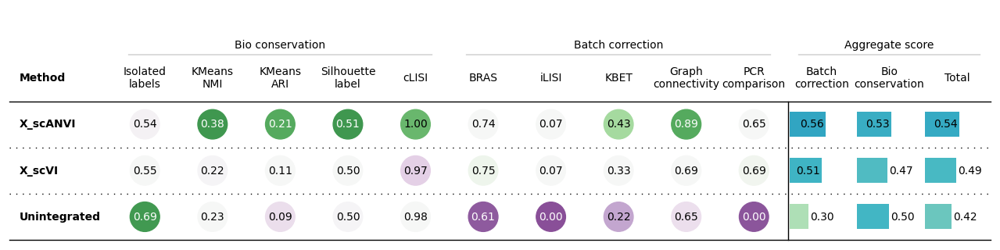

In [52]:
bm.plot_results_table(min_max_scale=False)

In [45]:
df.T

Embedding,Unintegrated,X_scVI,X_scANVI,Metric Type
Isolated labels,0.689515,0.547942,0.540353,Bio conservation
KMeans NMI,0.226688,0.222323,0.380992,Bio conservation
KMeans ARI,0.092699,0.114032,0.206199,Bio conservation
Silhouette label,0.499905,0.500247,0.514543,Bio conservation
cLISI,0.979436,0.972828,0.9963,Bio conservation
BRAS,0.611827,0.751281,0.740182,Batch correction
iLISI,0.000334,0.074188,0.073772,Batch correction
KBET,0.221186,0.325972,0.432051,Batch correction
Graph connectivity,0.650406,0.692971,0.889248,Batch correction
PCR comparison,0.0,0.686778,0.648868,Batch correction
